# Machine Learning Project | Milestone 1: Exploratory Data Analysis (EDA)

This notebook examines 79,330 reservations from the City Hotel dataset (July 2015 to August 2017) across 31 variables. We first check the schema, missing values, duplicate records, and recording errors. We then profile the numerical distributions and study the two supervised targets: booking cancellation for classification and average daily rate (ADR) for regression. The final sections audit all columns for target leakage at booking time and evaluate eight candidate features for customer segmentation.

## 1. Environment Setup and Data Loading

In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

file_path = None
for candidate in ['../data/raw/H2.csv', 'data/raw/H2.csv', 'H2.csv', '/content/H2.csv']:
    if os.path.exists(candidate):
        file_path = candidate
        break

if file_path is None:
    url = 'https://raw.githubusercontent.com/afaq-ahmad/Hotel-booking-demand-Case-Study/master/H2.csv'
    urllib.request.urlretrieve(url, 'H2.csv')
    file_path = 'H2.csv'

df = pd.read_csv(file_path)
print(f'Dataset successfully loaded from: {file_path}')
print(f'Total records: {df.shape[0]:,}')
print(f'Total variables: {df.shape[1]}')

Dataset successfully loaded from: H2.csv
Total records: 79,330
Total variables: 31


The City Hotel file loads 79,330 records across 31 variables. Each row corresponds to a single reservation.

## 2. Dataset Overview and Schema

In [2]:
schema_df = pd.DataFrame({
    'Column': df.columns,
    'Non-Null Count': df.notnull().sum().values,
    'Null Count': df.isnull().sum().values,
    'Null Pct (%)': np.round(df.isnull().mean().values * 100, 2),
    'Data Type': df.dtypes.astype(str).values,
    'Distinct Values': df.nunique().values,
    'Sample Value': [df[col].dropna().iloc[0] if len(df[col].dropna()) > 0 else 'N/A' for col in df.columns]
})
display(schema_df)
print(f'Memory usage: {df.memory_usage(deep=True).sum() / (1024 * 1024):.2f} MB')

,Column,Non-Null Count,Null Count,Null Pct (%),Data Type,Distinct Values,Sample Value
0,IsCanceled,79330,0,0.00,int64,2,0
1,LeadTime,79330,0,0.00,int64,453,6
2,ArrivalDateYear,79330,0,0.00,int64,3,2015
3,ArrivalDateMonth,79330,0,0.00,object,12,July
4,ArrivalDateWeekNumber,79330,0,0.00,int64,53,27
5,ArrivalDateDayOfMonth,79330,0,0.00,int64,31,1
6,StaysInWeekendNights,79330,0,0.00,int64,14,0
7,StaysInWeekNights,79330,0,0.00,int64,29,2
8,Adults,79330,0,0.00,int64,5,1
9,Children,79326,4,0.01,float64,4,0.0


Memory usage: 68.93 MB


Eighteen variables are numerical and thirteen are text (68.93 MB in memory). In the raw table, only children (4 records, 0.01%) and country (24 records, 0.03%) register standard nulls. Company and agent show no empty cells because their missing entries were exported as the literal string `NULL`, and several text columns carry leading or trailing whitespace. A few numeric columns have very small value sets and behave like discrete categories: cancellation and repeat-guest are binary (2 values), adults and babies take 5 values each, and children takes 4. Arrival dates are split across year, month, week, and day columns, while reservation status date is stored as text (864 distinct dates). No booking ID exists in the data.

Cardinality differs sharply across columns. Agent (224 levels), company (208), and country (166) are too wide for one-hot encoding and require frequency encoding or rare-level grouping. Market segment (8), distribution channel (5), customer type (4), and deposit type (3) have compact level sets that fit dummy encoding, while ADR (5,405 values) is continuous.

## 3. Data Quality, Missing Values, and Anomaly Audit

In [3]:
string_cols = df.select_dtypes(include=['object']).columns
for col in string_cols:
    df[col] = df[col].str.strip()

explicit_nulls = df.isnull().sum()[df.isnull().sum() > 0]
sentinel_nulls = {}
undefined_vals = {}

for col in string_cols:
    null_count = (df[col] == 'NULL').sum()
    if null_count > 0:
        sentinel_nulls[col] = null_count
    undef_count = (df[col] == 'Undefined').sum()
    if undef_count > 0:
        undefined_vals[col] = undef_count

quality_data = []
for col in set(list(explicit_nulls.index) + list(sentinel_nulls.keys()) + list(undefined_vals.keys())):
    exp = int(explicit_nulls.get(col, 0))
    sen = int(sentinel_nulls.get(col, 0))
    und = int(undefined_vals.get(col, 0))
    tot = exp + sen + und
    pct = (tot / len(df)) * 100
    quality_data.append({
        'Variable': col,
        'Explicit NaNs': exp,
        'Sentinel NULLs': sen,
        'Undefined': und,
        'Total Missing': tot,
        'Missing Pct (%)': np.round(pct, 3)
    })

quality_df = pd.DataFrame(quality_data).sort_values(by='Total Missing', ascending=False).reset_index(drop=True)
display(quality_df)

num_duplicates = df.duplicated().sum()
pct_duplicates = (num_duplicates / len(df)) * 100
print(f'Identical row duplicates: {num_duplicates:,} ({pct_duplicates:.2f}%)')

zero_guests = ((df['Adults'] == 0) & (df['Children'].fillna(0) == 0) & (df['Babies'] == 0)).sum()
print(f'Zero-guest records (Adults + Children + Babies == 0): {zero_guests} ({(zero_guests / len(df)) * 100:.3f}%)')

unaccompanied = ((df['Adults'] == 0) & ((df['Children'].fillna(0) > 0) | (df['Babies'] > 0))).sum()
print(f'Unaccompanied minors (Adults == 0, Children/Babies > 0): {unaccompanied} ({(unaccompanied / len(df)) * 100:.3f}%)')

zero_nights = ((df['StaysInWeekendNights'] == 0) & (df['StaysInWeekNights'] == 0)).sum()
print(f'Zero-night stays (Weekend + Week nights == 0): {zero_nights} ({(zero_nights / len(df)) * 100:.2f}%)')

room_p = (df['ReservedRoomType'] == 'P').sum()
print(f'Phantom room type P records: {room_p}')

,Variable,Explicit NaNs,Sentinel NULLs,Undefined,Total Missing,Missing Pct (%)
0,Company,0,75641,0,75641,95.350
1,Agent,0,8131,0,8131,10.250
2,Country,24,0,0,24,0.030
3,Children,4,0,0,4,0.005
4,DistributionChannel,0,0,4,4,0.005
5,MarketSegment,0,0,2,2,0.003


Identical row duplicates: 25,902 (32.65%)
Zero-guest records (Adults + Children + Babies == 0): 167 (0.211%)
Unaccompanied minors (Adults == 0, Children/Babies > 0): 223 (0.281%)
Zero-night stays (Weekend + Week nights == 0): 331 (0.42%)
Phantom room type P records: 10


Once padding spaces are stripped, six columns contain missing or placeholder entries. Company ID is `NULL` in 75,641 bookings (95.35%), so the raw identifier adds little value and can be dropped or reduced to a binary flag. Agent ID is `NULL` in 8,131 records (10.25%), which marks direct bookings made without an agency. Country has 24 empty records (0.03%). The 4 bookings missing children (0.005%) are the exact same 4 records where distribution channel is `Undefined` (2 of which also list market segment as `Undefined`).

Nearly a third of the dataset (25,902 rows, 32.65%) consists of exact duplicates across all 31 columns, which leaves 53,428 unique rows. Because there is no booking ID, we cannot tell log duplicates apart from multi-room group blocks entered as identical lines. Either way, rooms in a batch block share one outcome, so random splitting on the raw table would place identical copies in both train and test sets. Deduplicating before splitting prevents this leak.

Physical logic checks also catch three groups of invalid or unusual records: 167 bookings (0.21%) have zero total guests (including all 10 rows with phantom room code `P`), 223 bookings (0.28%) list children or babies with zero adults (390 total rows with zero adults), and 331 bookings (0.42%) list zero stay nights (all with zero ADR). Zero-guest and zero-night records should be removed before modeling.

## 4. Descriptive Statistics of Numerical Variables

In [4]:
num_cols = df.select_dtypes(include=[np.number]).columns
desc_stats = df[num_cols].describe().T
desc_stats['skewness'] = df[num_cols].skew()
desc_stats['kurtosis'] = df[num_cols].kurtosis()
desc_stats = desc_stats[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness', 'kurtosis']]
desc_stats = np.round(desc_stats, 2)
display(desc_stats)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
IsCanceled,79330.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0,0.34,-1.89
LeadTime,79330.0,109.74,110.95,0.0,23.0,74.0,163.0,629.0,1.39,1.80
ArrivalDateYear,79330.0,2016.17,0.70,2015.0,2016.0,2016.0,2017.0,2017.0,-0.25,-0.95
ArrivalDateWeekNumber,79330.0,27.18,13.40,1.0,17.0,27.0,38.0,53.0,-0.01,-0.96
ArrivalDateDayOfMonth,79330.0,15.79,8.73,1.0,8.0,16.0,23.0,31.0,-0.01,-1.18
StaysInWeekendNights,79330.0,0.80,0.89,0.0,0.0,1.0,2.0,16.0,1.13,5.00
StaysInWeekNights,79330.0,2.18,1.46,0.0,1.0,2.0,3.0,41.0,2.96,32.49
Adults,79330.0,1.85,0.51,0.0,2.0,2.0,2.0,4.0,-0.43,1.11
Children,79326.0,0.09,0.37,0.0,0.0,0.0,0.0,3.0,4.34,18.78
Babies,79330.0,0.00,0.08,0.0,0.0,0.0,0.0,10.0,44.78,4229.92


Most of the 18 numerical variables are right-skewed with heavy upper tails. Lead time averages 109.74 days against a median of 74 days (IQR 23 to 163, max 629, skewness 1.39). ADR averages 105.30 EUR (median 99.90, std 43.60), but a single 5,400 EUR entry drives its skewness to 23.16 and its kurtosis to 2,741.52. Four sparse history and modification counts (previous cancellations, previous non-canceled bookings, waiting list days, and booking changes) have a 75th percentile of zero alongside extreme maxima of 21, 72, 391, and 21. Two records listing 9 and 10 babies push babies kurtosis to 4,229.92. Because standard deviations span four orders of magnitude from 0.08 (babies) to 110.95 (lead time), linear and distance-based models require scaling and outlier handling.

## 5. Distributions of Key Variables

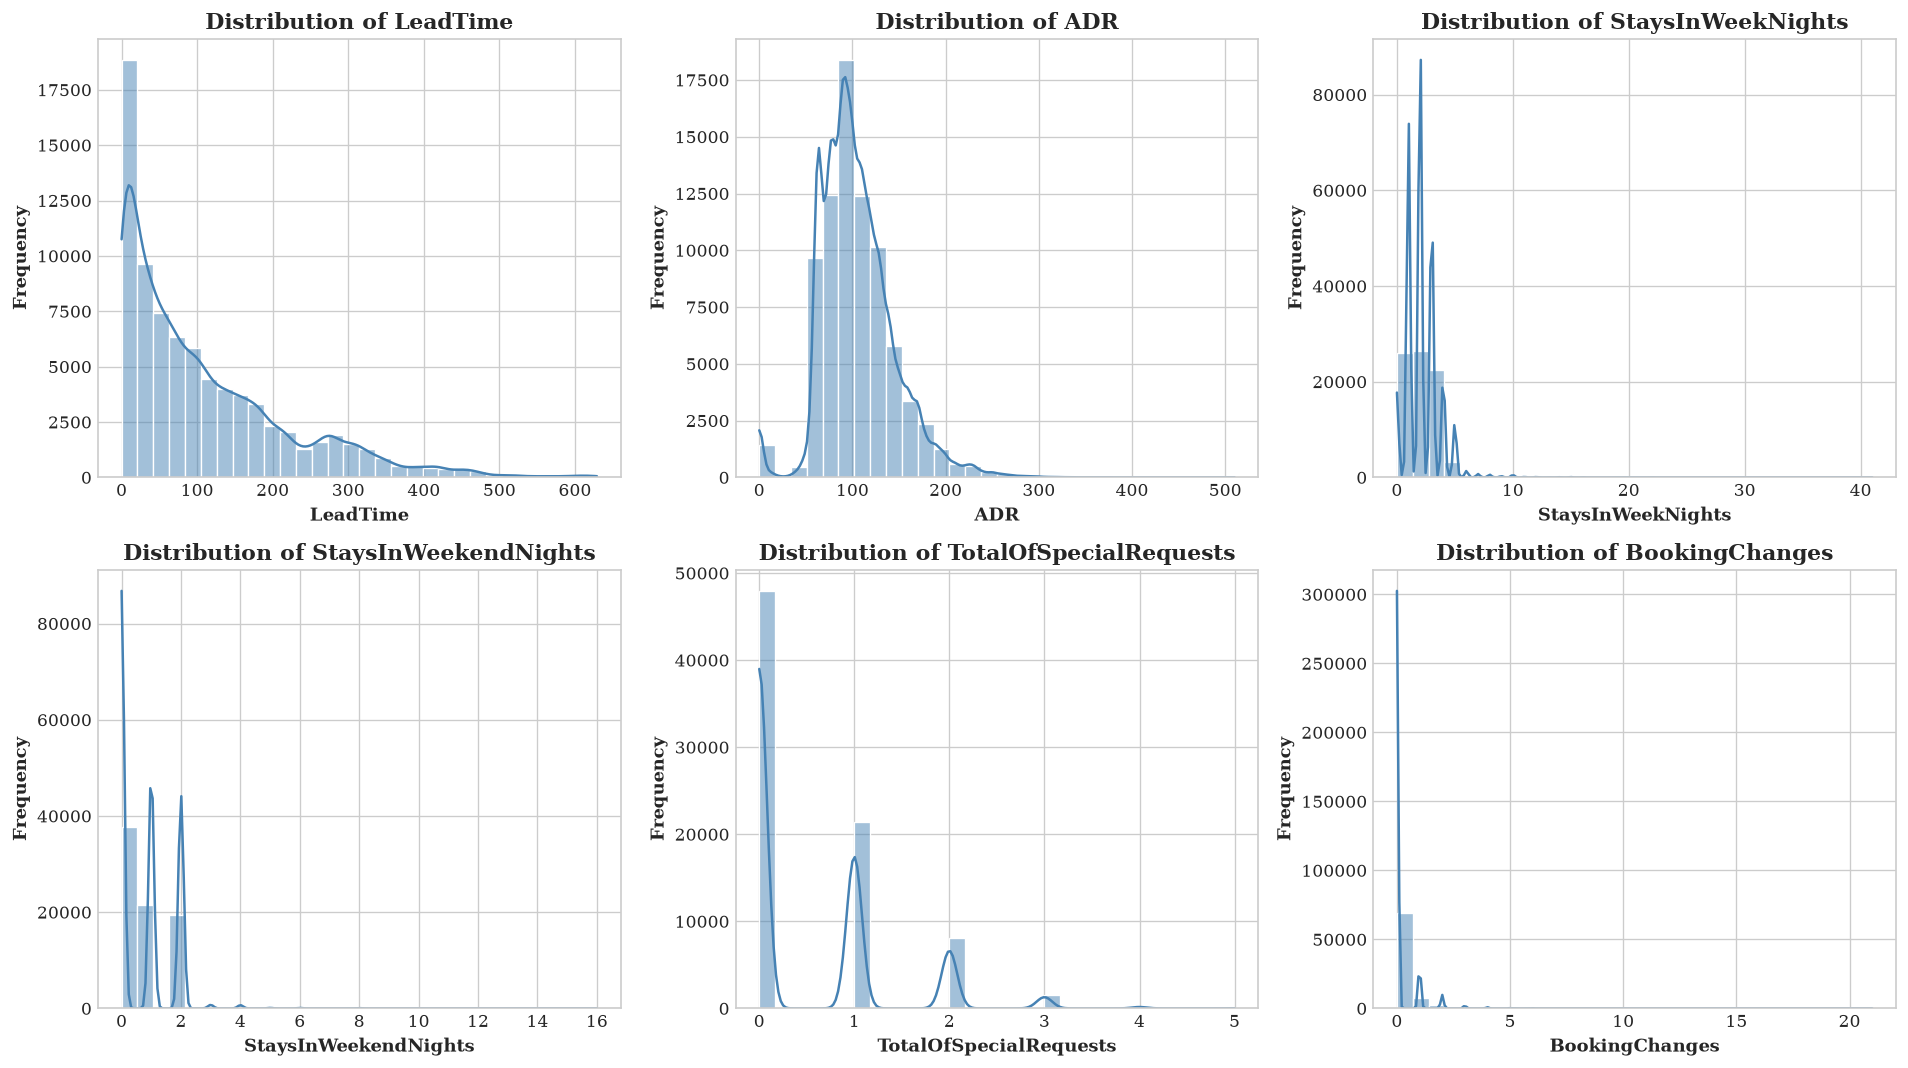

In [5]:
key_num_vars = ['LeadTime', 'ADR', 'StaysInWeekNights', 'StaysInWeekendNights', 'TotalOfSpecialRequests', 'BookingChanges']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, var in enumerate(key_num_vars):
    val_series = df[var].dropna()
    if var == 'ADR':
        val_series = val_series[val_series < 1000]
    sns.histplot(val_series, ax=axes[i], kde=True, color='steelblue', bins=30, edgecolor='white')
    axes[i].set_title(f'Distribution of {var}')
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

The six histograms divide into continuous right-skewed distributions and discrete counts. Lead time peaks near zero for short-notice bookings and tapers past 300 days, with small bumps between 150 and 350 days from advance tour blocks. Below 1,000 EUR, ADR sits mainly between 50 and 200 EUR around a 100 EUR mode, with sharp spikes at round prices (80, 100, and 120 EUR) and at 0 EUR (1,208 stays). Weeknight stays cluster at 1 to 3 nights and weekend stays sit at 0 to 2 nights, which matches typical short city trips. Special requests (60.45% zeros) and booking changes (84.88% zeros) are concentrated at zero, with very few bookings exceeding two requests or changes.

## 6. Target Analysis: Cancellation Behavior

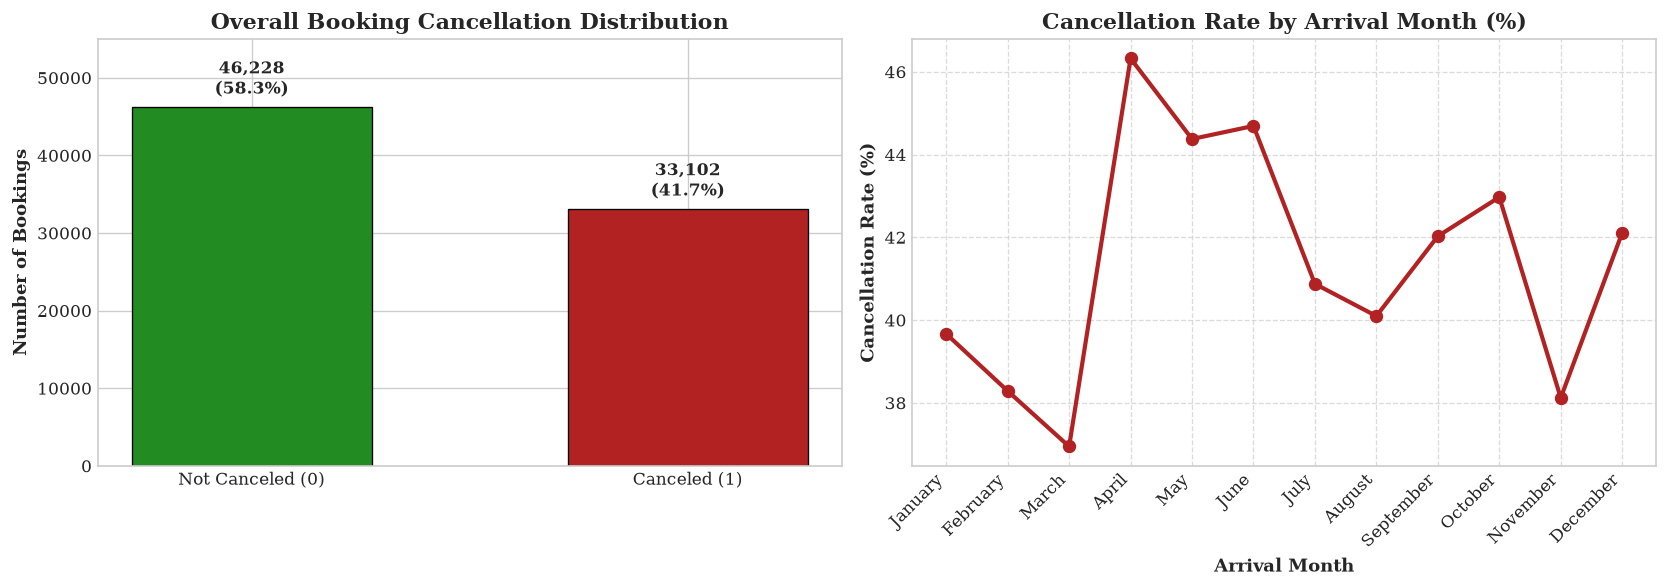

Not Canceled: 46,228 (58.27%)
Canceled: 33,102 (41.73%)


In [6]:
cancel_counts = df['IsCanceled'].value_counts()
cancel_pcts = df['IsCanceled'].value_counts(normalize=True) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

bars = ax1.bar(['Not Canceled (0)', 'Canceled (1)'], cancel_counts.values, color=['forestgreen', 'firebrick'], width=0.55, edgecolor='black', linewidth=0.8)
for bar in bars:
    height = bar.get_height()
    pct = (height / len(df)) * 100
    ax1.text(bar.get_x() + bar.get_width() / 2, height + 1000, f'{height:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.set_title('Overall Booking Cancellation Distribution')
ax1.set_ylabel('Number of Bookings')
ax1.set_ylim(0, 55000)

month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
monthly_cancel = df.groupby('ArrivalDateMonth')['IsCanceled'].mean().reindex(month_order) * 100
ax2.plot(range(len(month_order)), monthly_cancel.values, marker='o', color='firebrick', linewidth=2.5, markersize=7)
ax2.set_title('Cancellation Rate by Arrival Month (%)')
ax2.set_xlabel('Arrival Month')
ax2.set_ylabel('Cancellation Rate (%)')
ax2.set_xticks(range(len(month_order)))
ax2.set_xticklabels(month_order, rotation=45, ha='right')
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

print(f'Not Canceled: {cancel_counts[0]:,} ({cancel_pcts[0]:.2f}%)')
print(f'Canceled: {cancel_counts[1]:,} ({cancel_pcts[1]:.2f}%)')

Of the 79,330 reservations, 46,228 (58.27%) were honored and 33,102 (41.73%) were canceled. Class imbalance is mild, so stratified splitting and standard classification metrics (ROC-AUC and F1) can be used without synthetic oversampling. Across the calendar year, monthly cancellation rates stay within a narrow 9.37-point band. Rates peak in spring and early summer during April (46.32%), June (44.69%), and May (44.38%), and dip lowest in March (36.95%), November (38.12%), and February (38.29%). Because this seasonal spread is small next to the differences across deposit types and sales channels, arrival month carries limited predictive power on its own.

## 7. Target Analysis: Average Daily Rate

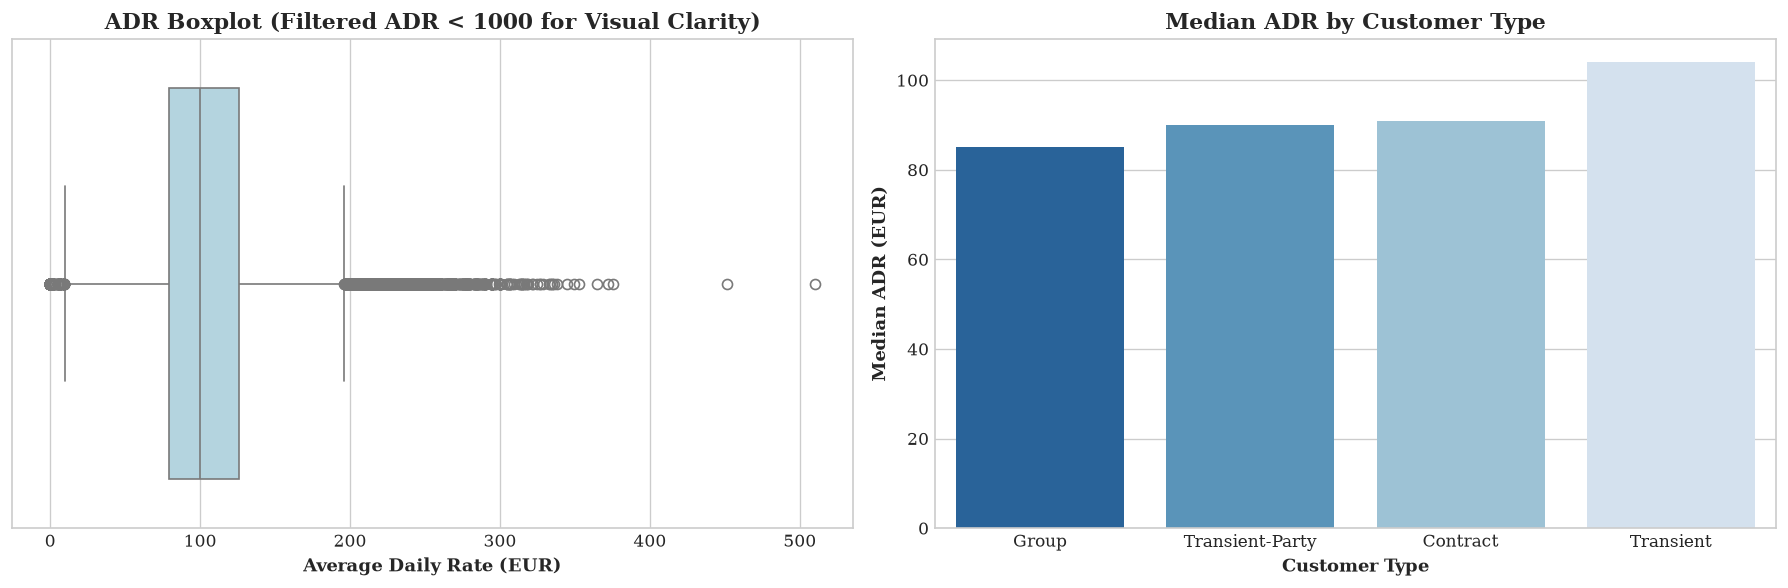

ADR Mean: 105.30, Median: 99.90, Std: 43.60
ADR Min: 0.00, Max: 5400.00
Interquartile Range (IQR): [79.20, 126.00], Length: 46.80
Tukey Outlier Bounds: [9.00, 196.20]
Number of Outliers: 3,387 (4.27%)
Zero-Rate Bookings (ADR == 0): 1,208 (1.52%)


In [7]:
q25, q50, q75 = df['ADR'].quantile([0.25, 0.5, 0.75])
iqr = q75 - q25
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr
outliers = df[(df['ADR'] < lower_bound) | (df['ADR'] > upper_bound)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(x=df[df['ADR'] < 1000]['ADR'], ax=ax1, color='lightblue')
ax1.set_title('ADR Boxplot (Filtered ADR < 1000 for Visual Clarity)')
ax1.set_xlabel('Average Daily Rate (EUR)')

customer_adr = df[df['ADR'] < 1000].groupby('CustomerType')['ADR'].median().sort_values()
sns.barplot(x=customer_adr.index, y=customer_adr.values, hue=customer_adr.index, ax=ax2, palette='Blues_r', legend=False)
ax2.set_title('Median ADR by Customer Type')
ax2.set_xlabel('Customer Type')
ax2.set_ylabel('Median ADR (EUR)')

plt.tight_layout()
plt.show()

print(f'ADR Mean: {df["ADR"].mean():.2f}, Median: {q50:.2f}, Std: {df["ADR"].std():.2f}')
print(f'ADR Min: {df["ADR"].min():.2f}, Max: {df["ADR"].max():.2f}')
print(f'Interquartile Range (IQR): [{q25:.2f}, {q75:.2f}], Length: {iqr:.2f}')
print(f'Tukey Outlier Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]')
print(f'Number of Outliers: {len(outliers):,} ({(len(outliers) / len(df)) * 100:.2f}%)')
print(f'Zero-Rate Bookings (ADR == 0): {(df["ADR"] == 0).sum():,} ({((df["ADR"] == 0).sum() / len(df)) * 100:.2f}%)')

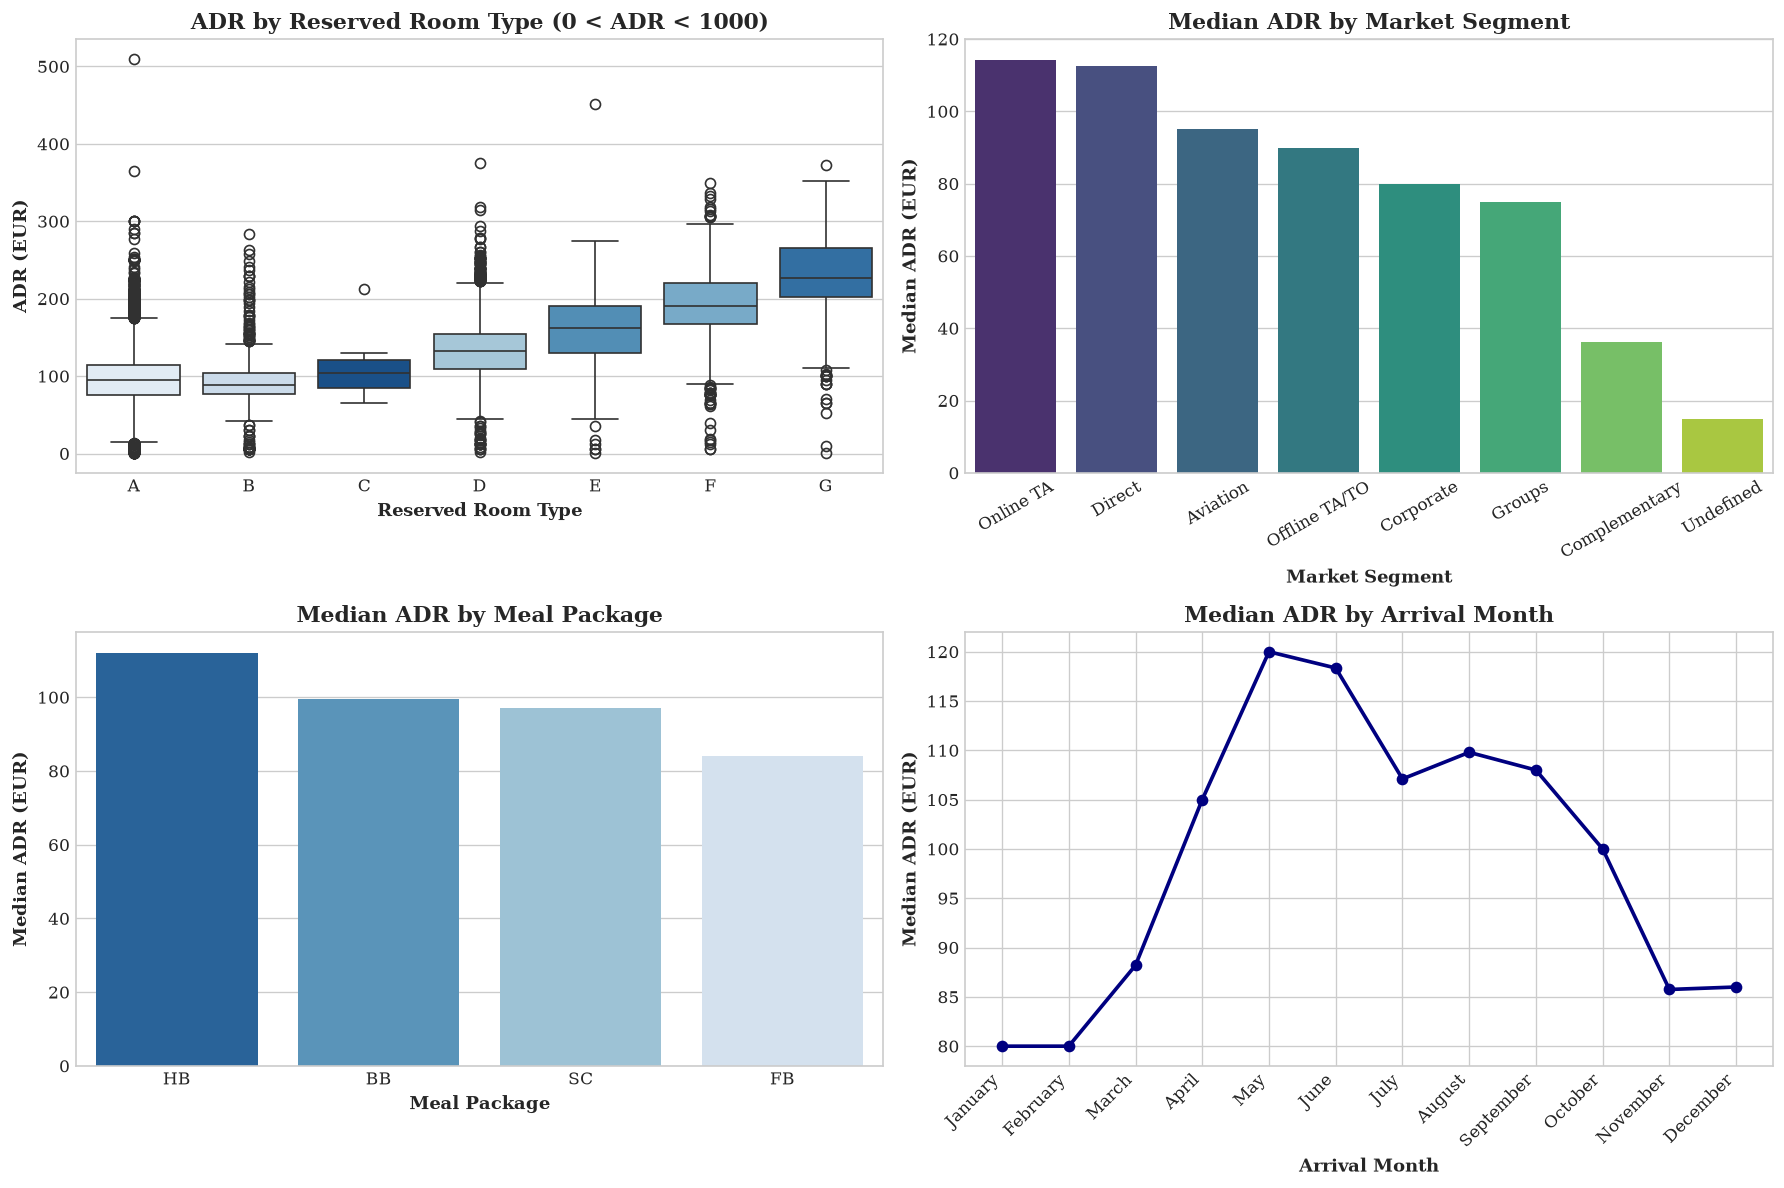

In [8]:
df_adr_clean = df[(df['ADR'] > 0) & (df['ADR'] < 1000)].copy()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

room_order = sorted(df_adr_clean['ReservedRoomType'].unique())
sns.boxplot(data=df_adr_clean, x='ReservedRoomType', y='ADR', order=room_order, hue='ReservedRoomType', ax=axes[0, 0], palette='Blues', legend=False)
axes[0, 0].set_title('ADR by Reserved Room Type (0 < ADR < 1000)')
axes[0, 0].set_xlabel('Reserved Room Type')
axes[0, 0].set_ylabel('ADR (EUR)')

seg_adr = df_adr_clean.groupby('MarketSegment')['ADR'].median().sort_values(ascending=False)
sns.barplot(x=seg_adr.index, y=seg_adr.values, hue=seg_adr.index, ax=axes[0, 1], palette='viridis', legend=False)
axes[0, 1].set_title('Median ADR by Market Segment')
axes[0, 1].set_xlabel('Market Segment')
axes[0, 1].set_ylabel('Median ADR (EUR)')
axes[0, 1].tick_params(axis='x', rotation=30)

meal_adr = df_adr_clean.groupby('Meal')['ADR'].median().sort_values(ascending=False)
sns.barplot(x=meal_adr.index, y=meal_adr.values, hue=meal_adr.index, ax=axes[1, 0], palette='Blues_r', legend=False)
axes[1, 0].set_title('Median ADR by Meal Package')
axes[1, 0].set_xlabel('Meal Package')
axes[1, 0].set_ylabel('Median ADR (EUR)')

monthly_adr = df_adr_clean.groupby('ArrivalDateMonth')['ADR'].median().reindex(month_order)
axes[1, 1].plot(range(len(month_order)), monthly_adr.values, marker='o', color='navy', linewidth=2.2)
axes[1, 1].set_title('Median ADR by Arrival Month')
axes[1, 1].set_xlabel('Arrival Month')
axes[1, 1].set_ylabel('Median ADR (EUR)')
axes[1, 1].set_xticks(range(len(month_order)))
axes[1, 1].set_xticklabels(month_order, rotation=45, ha='right')

plt.tight_layout()
plt.show()

The middle half of ADR spans 79.20 to 126.00 EUR (IQR 46.80 EUR), which puts the Tukey outlier fences at 9.00 and 196.20 EUR. Exactly 3,387 bookings (4.27%) fall outside those bounds. On the low end, 1,208 bookings (1.52%) have an ADR of 0 EUR from complimentary stays, zero-night records, or billing adjustments. On the high end, legitimate suite tariffs cluster between 196.20 and 510 EUR, whereas a single 5,400 EUR entry sits more than 121 standard deviations above the mean. Dropping the 5,400 EUR error and filtering zero-rate stays are required before fitting squared-error regression models.

Customer type creates a 19 EUR gap in median rate, from 85 EUR for groups and 90 EUR for transient-party bookings up to 90.95 EUR for contract and 104 EUR for individual transient guests. Room tier, sales channel, meal package, and season drive much larger price differences among positive rates below 1,000 EUR. Median ADR climbs steadily across room tiers from 88.77 EUR (`B`) and 94.50 EUR (`A`) to 132.30 EUR (`D`), 162 EUR (`E`), 190 EUR (`F`), and 227.25 EUR (`G`). Retail channels (Online TA at 114.30 EUR and Direct at 112.50 EUR) charge substantially more than negotiated volume segments (Offline TA/TO at 90 EUR, Corporate at 80 EUR, and Groups at 75 EUR). Half-board packages average a median of 112.10 EUR versus 99.45 EUR for bed-and-breakfast and 97.02 EUR for self-catering, while monthly medians rise by 50% from 80 EUR in January and February to 120 EUR in May and 118.35 EUR in June.

## 8. Rank Correlations Among Numerical Variables

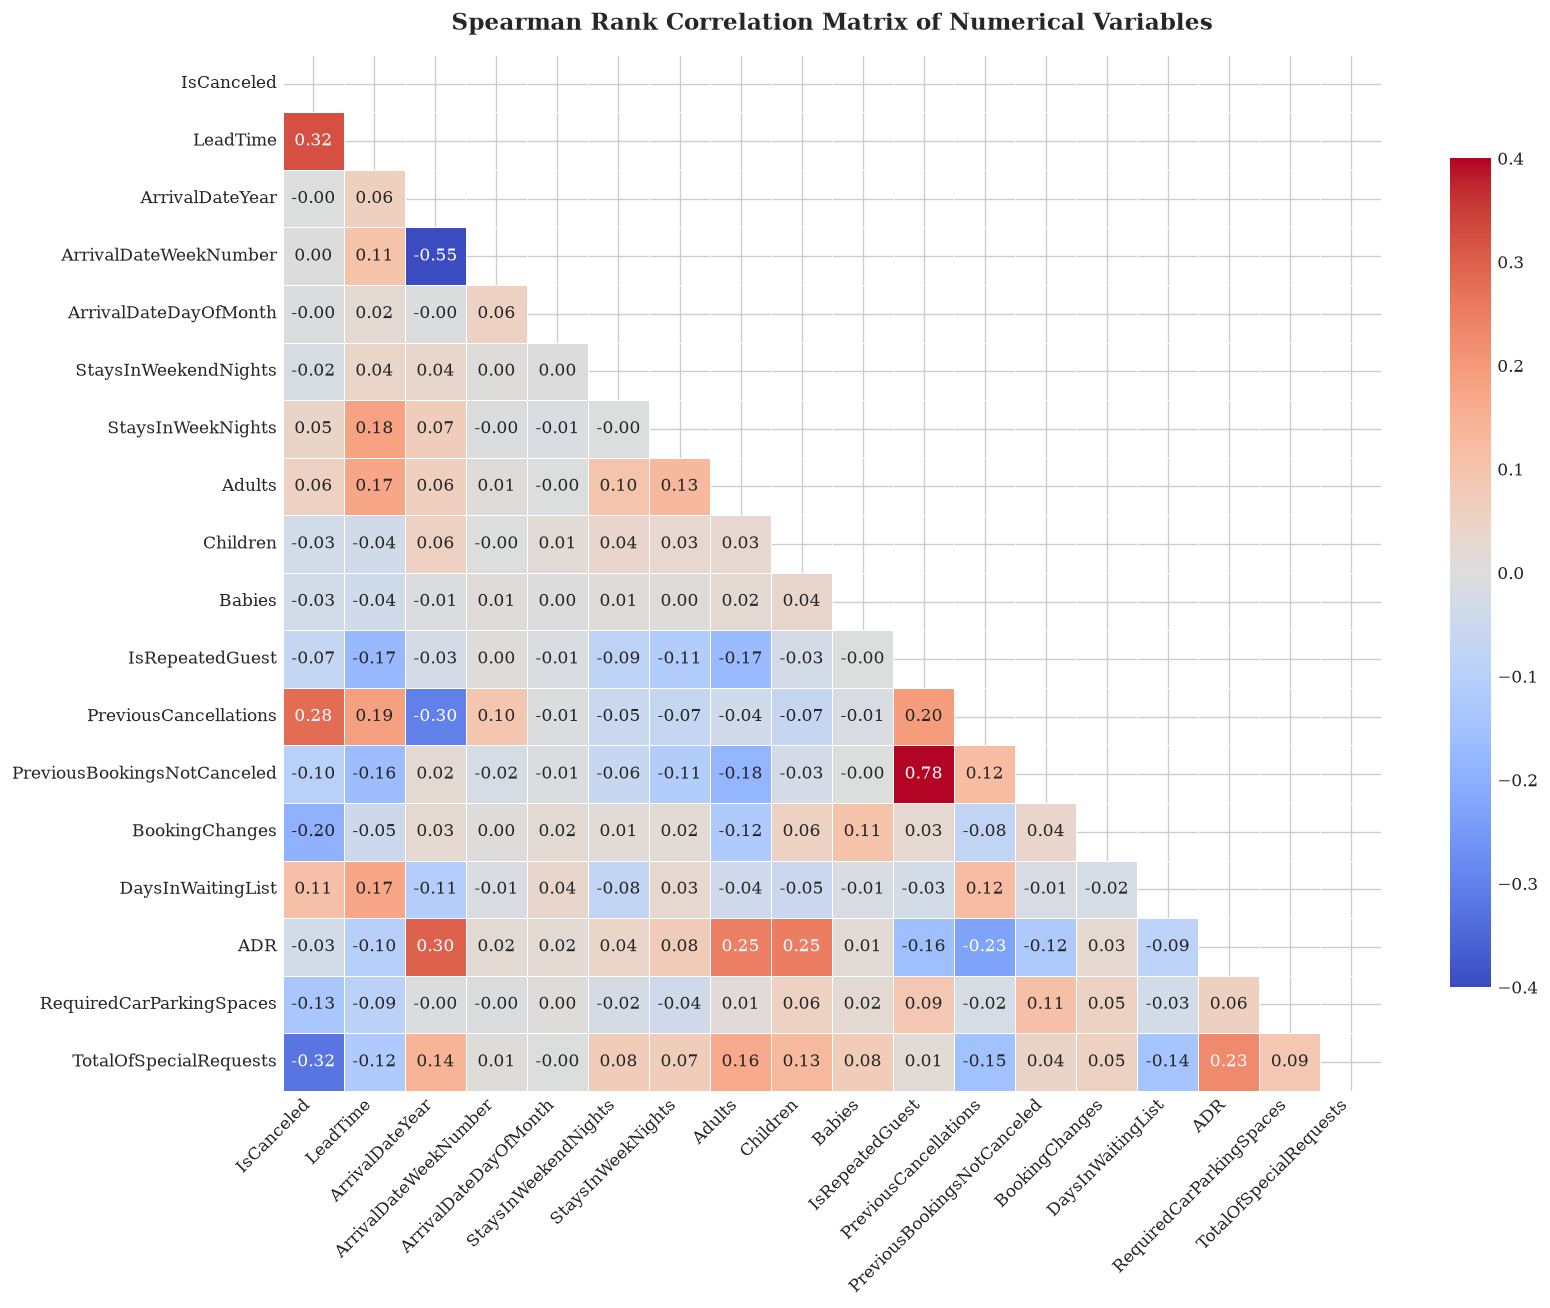

,Spearman Correlation with IsCanceled
LeadTime,0.325
PreviousCancellations,0.280
DaysInWaitingList,0.112
Adults,0.056
StaysInWeekNights,0.046
ArrivalDateWeekNumber,0.001
ArrivalDateYear,-0.001
ArrivalDateDayOfMonth,-0.004
StaysInWeekendNights,-0.018
ADR,-0.031


In [9]:
corr_vars = [
    'IsCanceled', 'LeadTime', 'ArrivalDateYear', 'ArrivalDateWeekNumber',
    'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights',
    'Adults', 'Children', 'Babies', 'IsRepeatedGuest',
    'PreviousCancellations', 'PreviousBookingsNotCanceled',
    'BookingChanges', 'DaysInWaitingList', 'ADR',
    'RequiredCarParkingSpaces', 'TotalOfSpecialRequests'
]

corr_matrix = df[corr_vars].corr(method='spearman')

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', vmin=-0.4, vmax=0.4, center=0, annot=True, fmt='.2f', linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Spearman Rank Correlation Matrix of Numerical Variables', fontsize=14, weight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

top_corr_cancel = corr_matrix['IsCanceled'].drop('IsCanceled').sort_values(ascending=False)
display(pd.DataFrame({'Spearman Correlation with IsCanceled': np.round(top_corr_cancel, 3)}))

We use Spearman rank correlation ($\rho$) across the 18 numerical variables to measure monotonic associations without assuming linear relationships or normal tails. Six variables exceed $|\rho| = 0.10$ with cancellation. Longer lead times ($+0.325$), prior cancellations ($+0.280$), and waiting-list days ($+0.112$) align with higher cancellation risk, whereas special requests ($-0.324$), booking changes ($-0.196$), and required parking spaces ($-0.133$) align with lower risk. Raw calendar variables (arrival year, week, and day) show almost zero rank correlation with cancellation ($|\rho| < 0.005$).

Among predictors, the repeat-guest flag and previous non-canceled bookings are largely redundant ($\rho = +0.78$). Arrival year and week number correlate negatively ($\rho = -0.55$) because the observation window starts in July 2015 and ends in August 2017, so 2015 covers only the second half of the year and 2017 covers only the first eight months. ADR increases with arrival year ($\rho = +0.30$), party size (adults $+0.25$, children $+0.25$), and special requests ($\rho = +0.23$).

## 9. Categorical Drivers of Cancellation

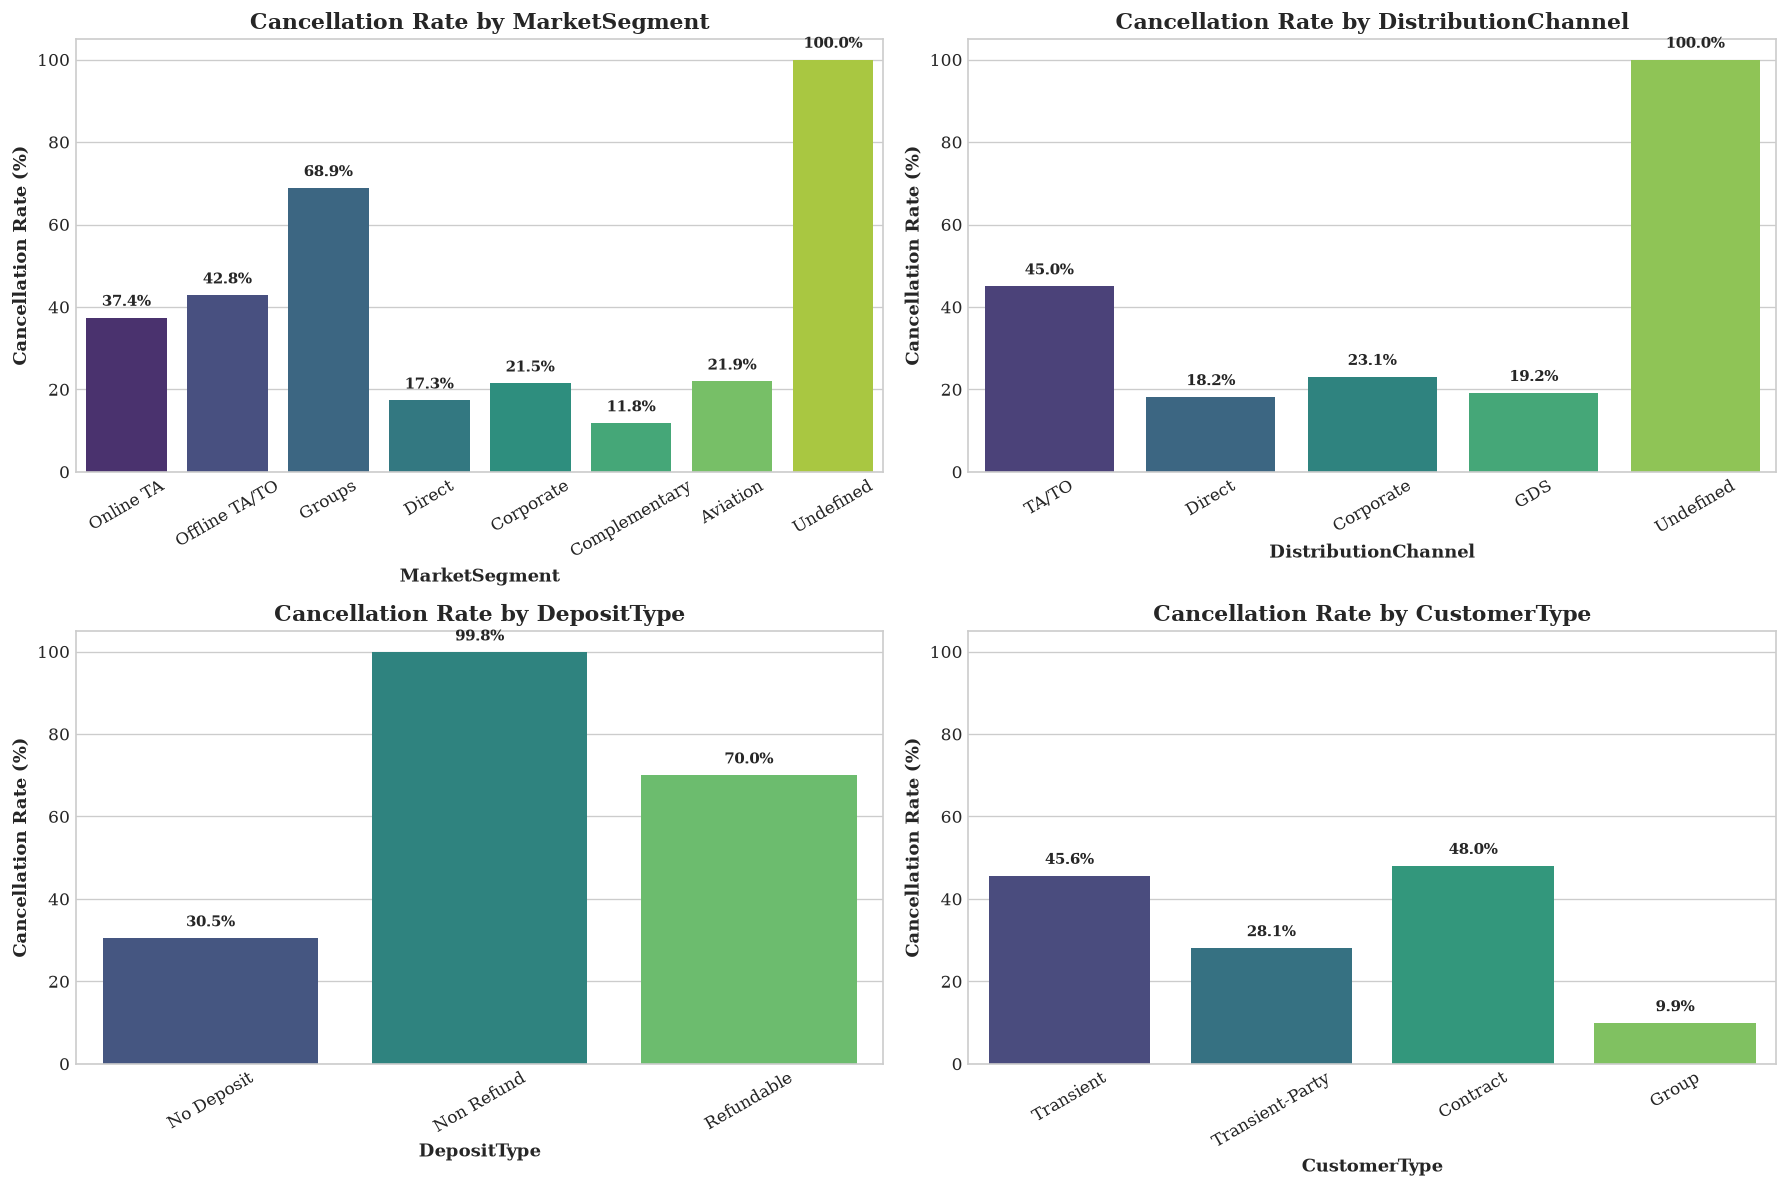

,Total_Bookings,Canceled_Bookings,Cancel_Rate_Pct
DepositType,,,
No Deposit,66442,20244,30.47
Non Refund,12868,12844,99.81
Refundable,20,14,70.00


In [10]:
cat_features = ['MarketSegment', 'DistributionChannel', 'DepositType', 'CustomerType']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    group = df.groupby(col).agg(Total=('IsCanceled', 'count'), CancelRate=('IsCanceled', 'mean')).reset_index()
    group['CancelRate'] = group['CancelRate'] * 100
    group = group.sort_values(by='Total', ascending=False)

    sns.barplot(data=group, x=col, y='CancelRate', hue=col, ax=axes[i], palette='viridis', legend=False)
    axes[i].set_title(f'Cancellation Rate by {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Cancellation Rate (%)')
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].set_ylim(0, 105)

    for p in axes[i].patches:
        axes[i].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() + 2), ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

deposit_summary = df.groupby('DepositType').agg(
    Total_Bookings=('IsCanceled', 'count'),
    Canceled_Bookings=('IsCanceled', 'sum'),
    Cancel_Rate_Pct=('IsCanceled', lambda x: np.round(x.mean() * 100, 2))
)
display(deposit_summary)

,Bookings,Share_Pct,Cancel_Rate_Pct
Country,,,
PRT,30960,39.03,64.86
FRA,8804,11.10,19.57
DEU,6084,7.67,17.62
GBR,5315,6.70,29.39
ESP,4611,5.81,28.76
ITA,3307,4.17,37.89
BEL,1894,2.39,21.91
BRA,1794,2.26,40.64
USA,1618,2.04,26.51


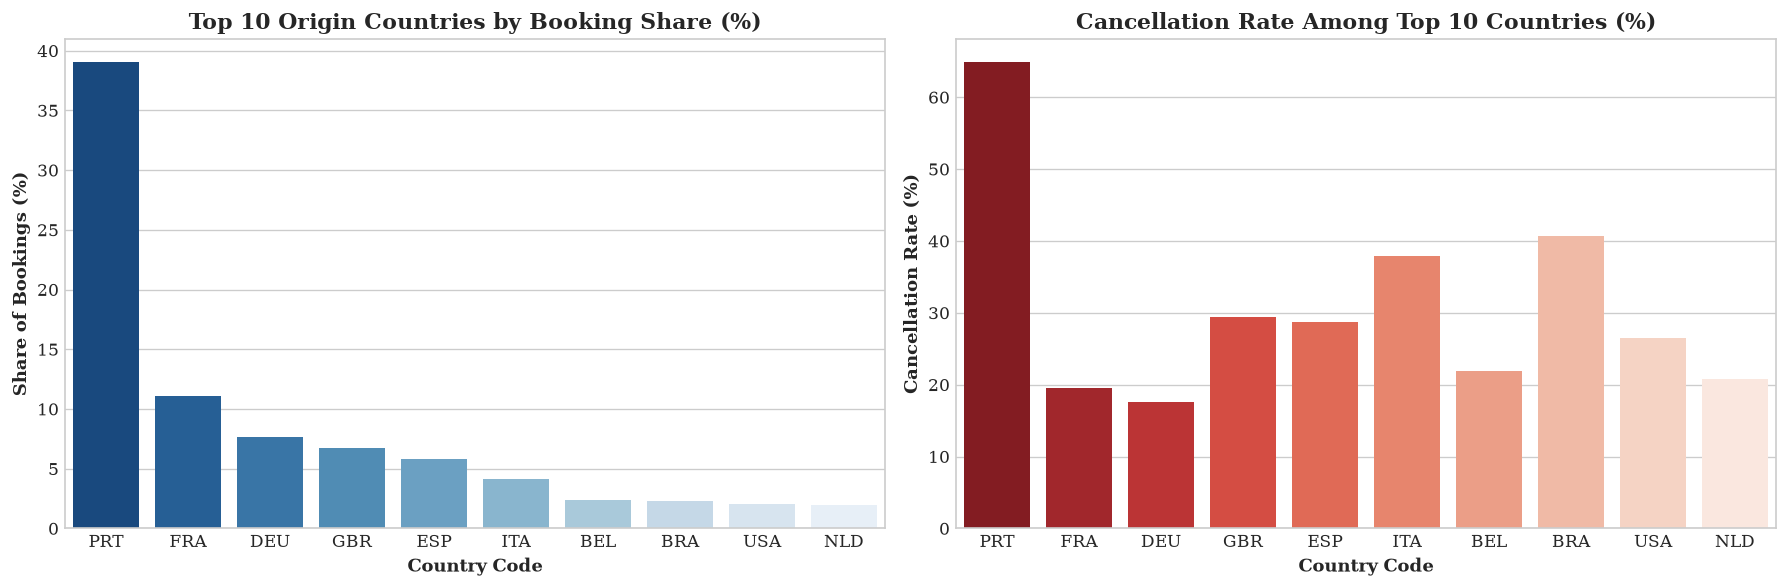

In [11]:
top10_countries = df['Country'].value_counts(dropna=False).head(10).index
country_stats = df[df['Country'].isin(top10_countries)].groupby('Country').agg(
    Bookings=('IsCanceled', 'count'),
    Share_Pct=('IsCanceled', lambda x: np.round(len(x) / len(df) * 100, 2)),
    Cancel_Rate_Pct=('IsCanceled', lambda x: np.round(x.mean() * 100, 2))
).loc[top10_countries]
display(country_stats)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=country_stats.index, y=country_stats['Share_Pct'], hue=country_stats.index, ax=ax1, palette='Blues_r', legend=False)
ax1.set_title('Top 10 Origin Countries by Booking Share (%)')
ax1.set_xlabel('Country Code')
ax1.set_ylabel('Share of Bookings (%)')

sns.barplot(x=country_stats.index, y=country_stats['Cancel_Rate_Pct'], hue=country_stats.index, ax=ax2, palette='Reds_r', legend=False)
ax2.set_title('Cancellation Rate Among Top 10 Countries (%)')
ax2.set_xlabel('Country Code')
ax2.set_ylabel('Cancellation Rate (%)')

plt.tight_layout()
plt.show()

Deposit policy produces the sharpest contrast in the dataset: Non Refund bookings cancel at 99.81% (12,844 of 12,868) compared to 30.47% for No Deposit. As shown in Section 11, this pattern is an artifact of bulk group blocks, since 93.4% of Non Refund rows are exact duplicates canceled together. Third-party and group channels also cancel heavily: Groups reaches 68.86%, Offline TA/TO 42.83%, Online TA 37.40%, and the TA/TO channel 45.03%, whereas Direct bookings (17.33%) and Complementary stays (11.81%) stay low. By customer type, Contract (48.04%) and Transient (45.62%) cancel far more often than Transient-Party (28.10%) and Group (9.90%).

Although guest origin spans 166 country codes, the top 10 countries account for 65,977 bookings, or 83.17% of the dataset. Domestic reservations from Portugal (`PRT`) make up 39.03% of all records and cancel at 64.86%, whereas inbound travelers from Germany (17.62%), France (19.57%), the Netherlands (20.82%), Belgium (21.91%), the USA (26.51%), Spain (28.76%), and the UK (29.39%) cancel at less than half that rate. Keeping the top 10 to 15 countries and grouping the remaining codes into an `Other` category preserves this domestic-versus-foreign split without adding 166 sparse columns.

## 10. Lead Time, Special Requests, and Room Assignment

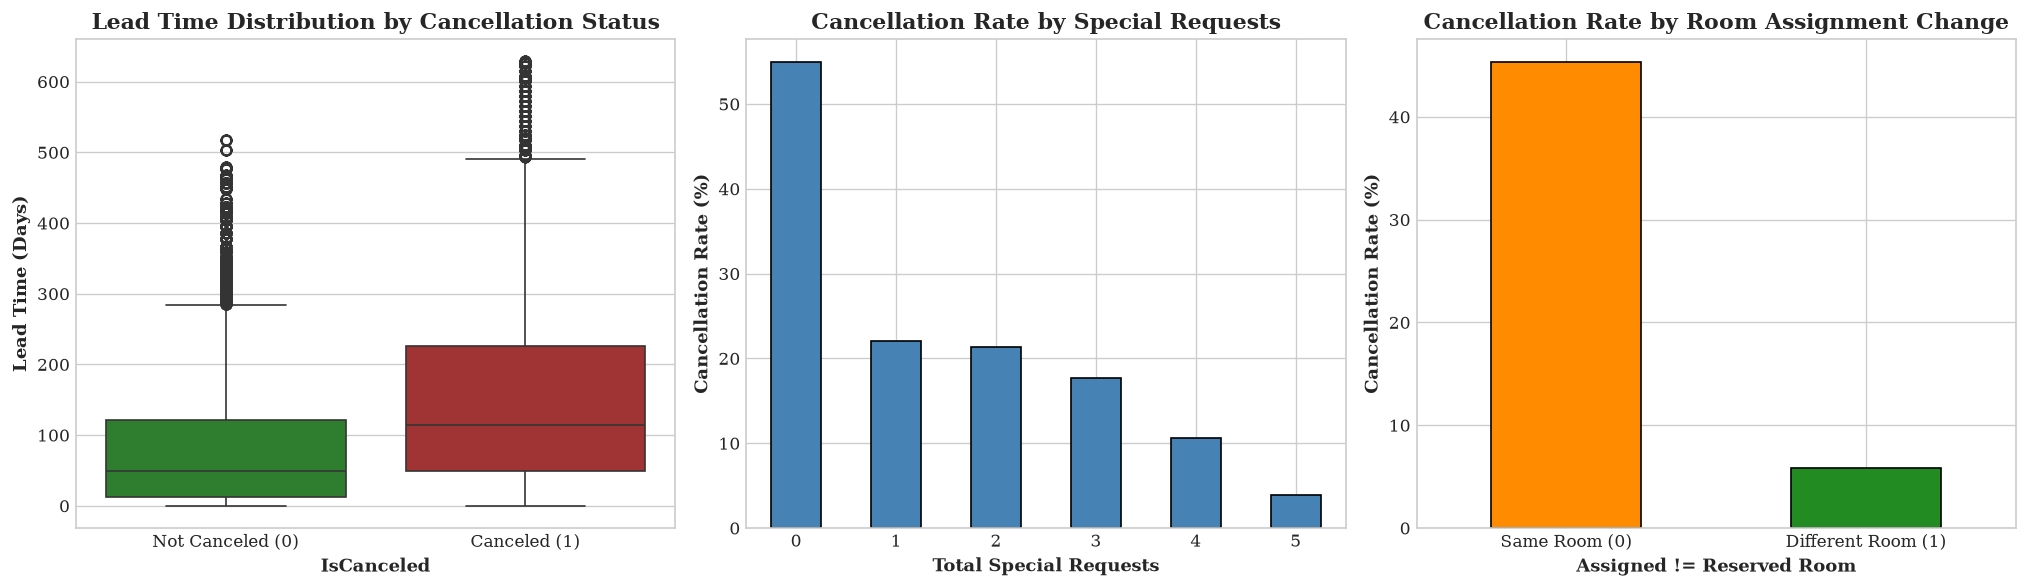

Mean Lead Time for Not Canceled: 80.7 days (Median: 50.0)
Mean Lead Time for Canceled: 150.3 days (Median: 115.0)
Discrepancy rate (Assigned != Reserved): 9.07%


In [12]:
df['RoomTypeDiscrepancy'] = (df['ReservedRoomType'] != df['AssignedRoomType']).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.boxplot(data=df, x='IsCanceled', y='LeadTime', hue='IsCanceled', ax=axes[0], palette=['forestgreen', 'firebrick'], legend=False)
axes[0].set_title('Lead Time Distribution by Cancellation Status')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Not Canceled (0)', 'Canceled (1)'])
axes[0].set_ylabel('Lead Time (Days)')

requests_cancel = df.groupby('TotalOfSpecialRequests')['IsCanceled'].mean() * 100
requests_cancel.plot(kind='bar', ax=axes[1], color='steelblue', edgecolor='black')
axes[1].set_title('Cancellation Rate by Special Requests')
axes[1].set_xlabel('Total Special Requests')
axes[1].set_ylabel('Cancellation Rate (%)')
axes[1].tick_params(axis='x', rotation=0)

room_cancel = df.groupby('RoomTypeDiscrepancy')['IsCanceled'].mean() * 100
room_cancel.plot(kind='bar', ax=axes[2], color=['darkorange', 'forestgreen'], edgecolor='black')
axes[2].set_title('Cancellation Rate by Room Assignment Change')
axes[2].set_xlabel('Assigned != Reserved Room')
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(['Same Room (0)', 'Different Room (1)'], rotation=0)
axes[2].set_ylabel('Cancellation Rate (%)')

plt.tight_layout()
plt.show()

print(f'Mean Lead Time for Not Canceled: {df[df["IsCanceled"] == 0]["LeadTime"].mean():.1f} days (Median: {df[df["IsCanceled"] == 0]["LeadTime"].median():.1f})')
print(f'Mean Lead Time for Canceled: {df[df["IsCanceled"] == 1]["LeadTime"].mean():.1f} days (Median: {df[df["IsCanceled"] == 1]["LeadTime"].median():.1f})')
print(f'Discrepancy rate (Assigned != Reserved): {df["RoomTypeDiscrepancy"].mean() * 100:.2f}%')

Canceled bookings are reserved much further in advance than completed stays, with a mean lead time of 150.3 days (median 115, IQR 50 to 226, max 629) versus 80.7 days (median 50, IQR 12 to 121, max 518) for guests who check in. Special requests show the opposite pattern: cancellation drops from 54.92% when guests make zero requests (47,957 rows) to 22.04% for one request and 3.85% for five requests. Room reassignments (where the assigned room differs from the reserved room, 9.07% of bookings) have a 5.81% cancellation rate compared to 45.31% when the room is unchanged. Because hotels reassign or upgrade rooms at check-in, the assigned room column leaks arrival information that is not known at booking time.

## 11. Target Leakage Audit

In [13]:
leakage_crosstab = pd.crosstab(df['ReservationStatus'], df['IsCanceled'], margins=True)
display(leakage_crosstab)

perfect_leakage = (
    ((df['ReservationStatus'] == 'Check-Out') & (df['IsCanceled'] == 0)).sum() +
    ((df['ReservationStatus'].isin(['Canceled', 'No-Show'])) & (df['IsCanceled'] == 1)).sum()
)
print(f'Exact mathematical consistency: {perfect_leakage} / {len(df)} ({(perfect_leakage / len(df)) * 100:.1f}%)')

parking_crosstab = pd.crosstab(df['RequiredCarParkingSpaces'], df['IsCanceled'], margins=True)
display(parking_crosstab)

df_dedup = df.drop(columns=['RoomTypeDiscrepancy']).drop_duplicates()
print(f'Deduplicated rows: {len(df_dedup):,} (Canceled rate: {df_dedup["IsCanceled"].mean() * 100:.2f}%)')
display(pd.crosstab(df_dedup['DepositType'], df_dedup['IsCanceled'], margins=True))

IsCanceled,0,1,All
ReservationStatus,,,
Canceled,0,32186,32186
Check-Out,46228,0,46228
No-Show,0,916,916
All,46228,33102,79330


Exact mathematical consistency: 79330 / 79330 (100.0%)


IsCanceled,0,1,All
RequiredCarParkingSpaces,,,
0,44302,33102,77404
1,1921,0,1921
2,3,0,3
3,2,0,2
All,46228,33102,79330


Deduplicated rows: 53,428 (Canceled rate: 30.04%)


IsCanceled,0,1,All
DepositType,,,
No Deposit,37350,15218,52568
Non Refund,24,821,845
Refundable,5,10,15
All,37379,16049,53428


We evaluate all predictors at the moment a booking is confirmed, prior to guest arrival. Reservation status is a direct restatement of the classification target across all 79,330 rows: `Check-Out` maps to 0, while `Canceled` (32,186 rows) and `No-Show` (916 rows) map to 1. Reservation status date logs when that final outcome was entered. Required parking spaces also leaks check-in activity: out of 1,926 bookings with 1 to 3 parking spaces, 0 were canceled because staff record parking spaces upon arrival.

Removing the 25,902 exact duplicate rows ($N = 53,428$) lowers the overall cancellation rate from 41.73% to 30.04% and cuts Non Refund volume from 12,868 rows to 845 unique rows (97.16% canceled), since 12,023 of those rows were duplicate group-block entries. Classification models must drop reservation status, status date, assigned room type, and parking spaces. ADR regression and customer segmentation must drop all four columns along with the cancellation target.

## 12. Feature Associations for Customer Segmentation

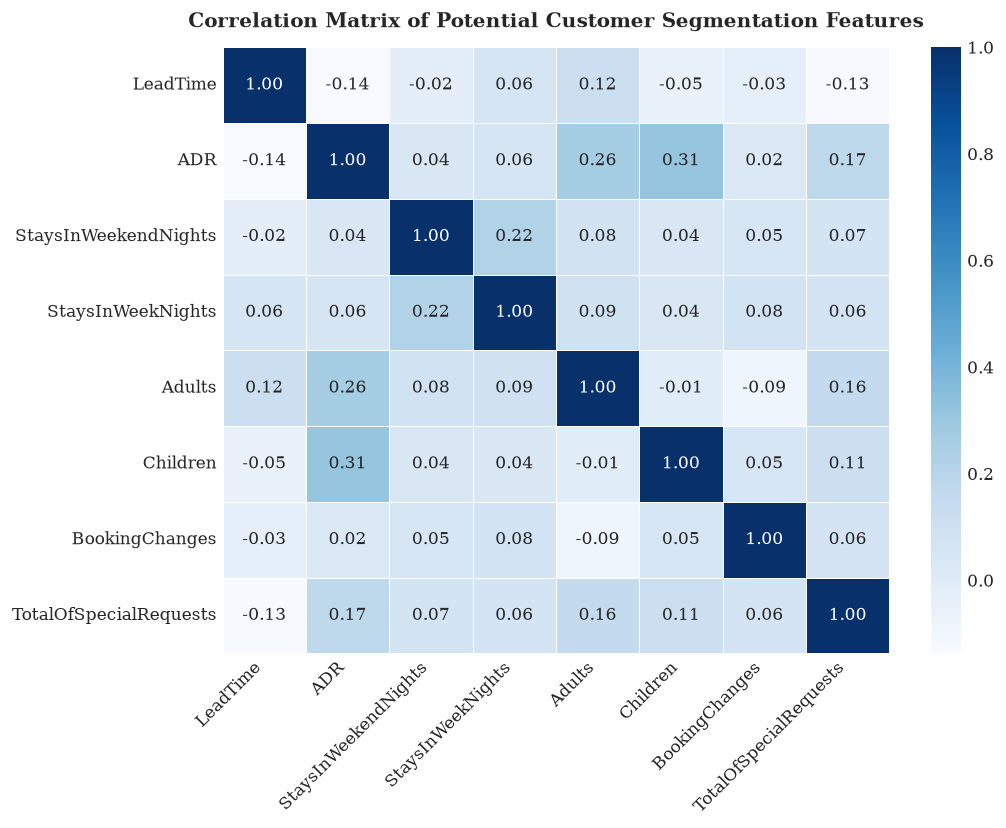

,mean,std,min,median,max
LeadTime,109.74,110.95,0.0,74.0,629.0
ADR,105.30,43.60,0.0,99.9,5400.0
StaysInWeekendNights,0.80,0.89,0.0,1.0,16.0
StaysInWeekNights,2.18,1.46,0.0,2.0,41.0
Adults,1.85,0.51,0.0,2.0,4.0
Children,0.09,0.37,0.0,0.0,3.0
BookingChanges,0.19,0.61,0.0,0.0,21.0
TotalOfSpecialRequests,0.55,0.78,0.0,0.0,5.0


In [14]:
cluster_features = [
    'LeadTime', 'ADR', 'StaysInWeekendNights', 'StaysInWeekNights',
    'Adults', 'Children', 'BookingChanges', 'TotalOfSpecialRequests'
]

cluster_corr = df[cluster_features].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(cluster_corr, annot=True, fmt='.2f', cmap='Blues', cbar=True, linewidths=0.5)
plt.title('Correlation Matrix of Potential Customer Segmentation Features', fontsize=12, weight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

cluster_summary = df[cluster_features].agg(['mean', 'std', 'min', 'median', 'max']).T
display(np.round(cluster_summary, 2))

Pairwise Pearson correlations across the eight candidate segmentation features stay at or below $|r| = 0.31$, with the strongest linear links connecting ADR to children ($+0.31$) and adults ($+0.26$) because larger parties book higher-priced rooms. This rules out linear collinearity among the eight features while still allowing nonlinear guest clusters to form in the joint space. However, feature scales differ by more than two orders of magnitude: standard deviations run from 0.37 (children) and 0.51 (adults) up to 43.60 (ADR) and 110.95 (lead time), with maxima at 5,400 EUR and 629 days. Removing the 5,400 EUR outlier, capping extreme tails, and standardizing the features are necessary so lead time and ADR do not dominate Euclidean distance in PCA or K-Means.